# 01 Explore: South African electricity demand, April 2022 to October 2026

**Project:** forecast South Africa's hourly electricity demand one week ahead, and compare it with simple baselines and with Eskom's own published forecast.
**This notebook:** loads the Eskom data and documents the columns (Step 2), then explores trend, cycles, solar and load-shedding effects (Step 3).

**Data:** Eskom Data Portal ([eskom.co.za/dataportal](https://www.eskom.co.za/dataportal/)), requested through the [data request form](https://www.eskom.co.za/dataportal/data-request-form/) for the full available period (1 April 2022 to 31 March 2027). The download link arrives by email; the file is saved in `data/raw/`. Eskom's terms apply, so the raw file is not committed to this repository.

## 1. Load the data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

files = sorted(Path("../data/raw").glob("*.csv"))
if not files:
    raise FileNotFoundError("Request the data from https://www.eskom.co.za/dataportal/data-request-form/ "
                            "and save the CSV in data/raw/ (see README).")
raw = pd.read_csv(files[0])
print(files[0].name, raw.shape)
raw.head()

ESK19906.csv (43824, 17)


,Date Time Hour Beginning,Original Res Forecast before Lockdown,Residual Forecast,RSA Contracted Forecast,Dispatchable Generation,Residual Demand,RSA Contracted Demand,Wind,PV,CSP,Other RE,Total RE,Wind Installed Capacity,PV Installed Capacity,CSP Installed Capacity,Other RE Installed Capacity,Total RE Installed Capacity
0,2022-04-01 12:00:00 AM,22160.133,21324.592,22106.655,21105.801,21105.801,22240.789,1091.744,0.0,0.0,43.244,1134.988,3163.37,2212.09,500.0,50.58,5926.04
1,2022-04-01 01:00:00 AM,21737.774,20908.936,21651.713,20936.935,20936.935,22043.880,1063.786,0.0,0.0,43.159,1106.945,3163.37,2212.09,500.0,50.58,5926.04
2,2022-04-01 02:00:00 AM,21706.565,20771.960,21466.049,20892.068,20892.068,21880.597,956.343,0.0,0.0,32.186,988.529,3163.37,2212.09,500.0,50.58,5926.04
3,2022-04-01 03:00:00 AM,21940.481,20896.331,21560.271,20964.935,20964.935,21993.023,986.865,0.0,0.0,41.223,1028.088,3163.37,2212.09,500.0,50.58,5926.04
4,2022-04-01 04:00:00 AM,23045.826,21987.801,22620.957,21886.935,21886.935,22914.172,984.148,0.0,0.0,43.089,1027.237,3163.37,2212.09,500.0,50.58,5926.04


In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 17 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Date Time Hour Beginning               43824 non-null  str    
 1   Original Res Forecast before Lockdown  6600 non-null   float64
 2   Residual Forecast                      43824 non-null  float64
 3   RSA Contracted Forecast                43824 non-null  float64
 4   Dispatchable Generation                39600 non-null  float64
 5   Residual Demand                        39600 non-null  float64
 6   RSA Contracted Demand                  39600 non-null  float64
 7   Wind                                   39600 non-null  float64
 8   PV                                     39600 non-null  float64
 9   CSP                                    39600 non-null  float64
 10  Other RE                               39600 non-null  float64
 11  Total RE     

## 2. Parse the timestamps and check coverage

In [3]:
raw["timestamp"] = pd.to_datetime(raw["Date Time Hour Beginning"], format="%Y-%m-%d %I:%M:%S %p")
eskom = raw.drop(columns="Date Time Hour Beginning").set_index("timestamp")
steps = eskom.index.to_series().diff().value_counts()
print(f"From {eskom.index.min()} to {eskom.index.max()}, {len(eskom):,} hours")
print(f"Duplicated hours: {eskom.index.duplicated().sum()},  step sizes: {steps.to_dict()}")
print("\nNon-missing values per column:")
print(eskom.notna().sum().to_string())

From 2022-04-01 00:00:00 to 2027-03-31 23:00:00, 43,824 hours
Duplicated hours: 0,  step sizes: {Timedelta('0 days 01:00:00'): 43823}

Non-missing values per column:
Original Res Forecast before Lockdown     6600
Residual Forecast                        43824
RSA Contracted Forecast                  43824
Dispatchable Generation                  39600
Residual Demand                          39600
RSA Contracted Demand                    39600
Wind                                     39600
PV                                       39600
CSP                                      39600
Other RE                                 39600
Total RE                                 39600
Wind Installed Capacity                  39600
PV Installed Capacity                    39600
CSP Installed Capacity                   39600
Other RE Installed Capacity              39600
Total RE Installed Capacity              39600


In [4]:
last_actual = eskom["RSA Contracted Demand"].last_valid_index()
print(f"Actual demand recorded until: {last_actual}")
print(f"After that only Eskom's forecasts are filled in, up to {eskom.index.max().date()}.")
actual = eskom.loc[:last_actual]
print(f"Hours of actual data: {len(actual):,} ({len(actual) / 24 / 365.25:.1f} years), missing demand values: "
      f"{actual['RSA Contracted Demand'].isna().sum()}")

Actual demand recorded until: 2026-10-06 23:00:00
After that only Eskom's forecasts are filled in, up to 2027-03-31.
Hours of actual data: 39,600 (4.5 years), missing demand values: 0


## 3. What the columns mean

From the [Eskom Data Portal glossary](https://www.eskom.co.za/dataportal/glossary/) and checks on the data:

| Column | Meaning (MW, hourly average) |
|---|---|
| `RSA Contracted Demand` | Demand that must be supplied by **all resources Eskom has contracts with**, including renewable independent power producers. **This is the target.** |
| `Residual Demand` | Demand to be supplied by resources **Eskom National Control can dispatch**: contracted demand minus wind, solar and other renewables. |
| `RSA Contracted Forecast`, `Residual Forecast` | Eskom's own forecasts of the two demands. Filled in for every hour, including future hours up to March 2027. |
| `Original Res Forecast before Lockdown` | An older residual forecast series, only in the first months. Not used. |
| `Dispatchable Generation` | What the dispatchable fleet actually generated |
| `Wind`, `PV`, `CSP`, `Other RE`, `Total RE` | Contracted renewable generation: wind, solar photovoltaic, concentrated solar power, other (small hydro, biomass, landfill gas) |
| `... Installed Capacity` | Installed capacity of each renewable type |

Two checks: contracted demand minus residual demand should equal total renewables, and residual demand should equal dispatchable generation unless something stopped demand from being supplied.

In [5]:
diff = (actual["RSA Contracted Demand"] - actual["Residual Demand"] - actual["Total RE"]).abs()
print(f"Contracted - residual - renewables: median {diff.median():.0f} MW, 95th percentile {diff.quantile(0.95):.0f} MW")
gap = actual["Residual Demand"] - actual["Dispatchable Generation"]
print(f"Hours where residual demand exceeds dispatchable generation: {(gap > 1).mean():.0%}, largest gap {gap.max():,.0f} MW")

Contracted - residual - renewables: median 0 MW, 95th percentile 106 MW
Hours where residual demand exceeds dispatchable generation: 37%, largest gap 6,836 MW


- Contracted minus residual demand matches renewable generation closely, which confirms the definitions. (The small differences are other contracted sources not broken out in the file.)
- In 37% of hours, residual demand is higher than what the dispatchable fleet generated, by up to 6,800 MW. Those hours cluster in 2022 and 2023, the years of heavy **load shedding**. The demand columns appear to include demand that was cut off, which is what a planner needs to forecast: how much the country **wants**, not only what it got. Step 3 looks at this in time.

---
# Step 3: Explore before any model

In [6]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

from datetime import date, timedelta

EASTER_SUNDAY = {2022: date(2022, 4, 17), 2023: date(2023, 4, 9), 2024: date(2024, 3, 31),
                 2025: date(2025, 4, 20), 2026: date(2026, 4, 5), 2027: date(2027, 3, 28)}
SPECIAL = {date(2023, 12, 15): "Rugby World Cup holiday", date(2024, 5, 29): "National elections"}

def sa_public_holidays(years):
    """South African public holidays (Public Holidays Act): a holiday on a Sunday moves to the next free day."""
    days = {}
    for y in years:
        fixed = {(1, 1): "New Year's Day", (3, 21): "Human Rights Day", (4, 27): "Freedom Day",
                 (5, 1): "Workers' Day", (6, 16): "Youth Day", (8, 9): "National Women's Day",
                 (9, 24): "Heritage Day", (12, 16): "Day of Reconciliation", (12, 25): "Christmas Day",
                 (12, 26): "Day of Goodwill"}
        for (m, d), name in fixed.items():
            days[date(y, m, d)] = name
        days[EASTER_SUNDAY[y] - timedelta(days=2)] = "Good Friday"
        days[EASTER_SUNDAY[y] + timedelta(days=1)] = "Family Day"
    for d in sorted(list(days)):
        if d.weekday() == 6:
            nxt = d + timedelta(days=1)
            while nxt in days:
                nxt += timedelta(days=1)
            days[nxt] = days[d] + " (observed)"
    days.update({d: n for d, n in SPECIAL.items() if d.year in years})
    return days

Average demand by calendar year (MW):
timestamp
2022    26064.0
2023    25785.0
2024    25006.0
2025    23922.0
2026    22538.0


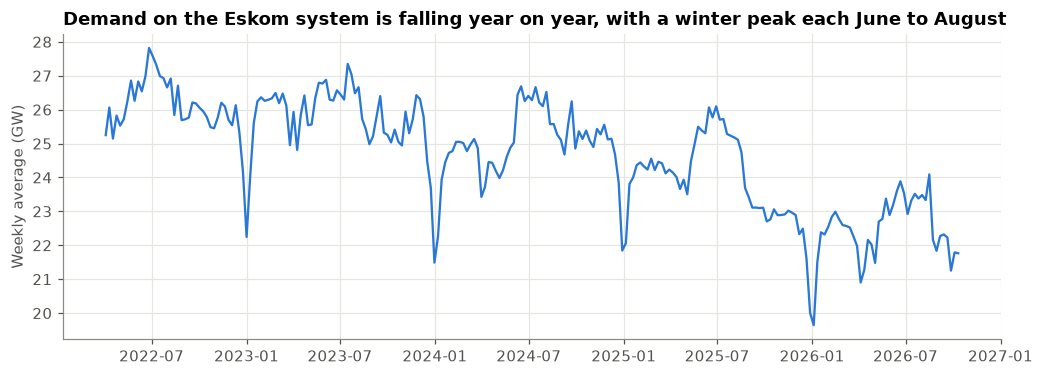

In [7]:
demand = actual["RSA Contracted Demand"].rename("demand")
weekly = demand.resample("W").mean() / 1000
yearly = demand.groupby(demand.index.year).mean().round(0)
print("Average demand by calendar year (MW):")
print(yearly.to_string())

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(weekly.index, weekly.values, color=BLUE, linewidth=1.5)
ax.set_ylabel("Weekly average (GW)")
ax.set_title("Demand on the Eskom system is falling year on year, with a winter peak each June to August")
fig.savefig("../figures/weekly_demand.png")
plt.show()

**Trend:** average contracted demand fell from about 26.1 GW in 2022 to about 22.5 GW so far in 2026, a drop of roughly 14%. The economy has not shrunk by that much; a large part of the drop is **rooftop solar** behind the meter, which Eskom does not see as demand at all, plus customers moving to their own generation after years of load shedding. A forecasting model has to handle a level that keeps moving down.

**Seasonality:** a clear winter peak every year (June to August), when heating adds load, and a dip over the December holidays.

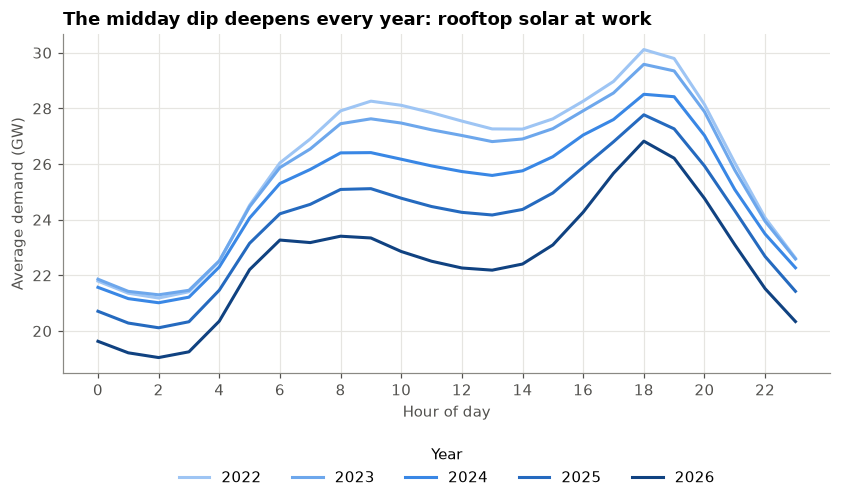

In [8]:
profile = demand.groupby([demand.index.year, demand.index.hour]).mean().unstack(0) / 1000
fig, ax = plt.subplots(figsize=(9, 4))
shades = ["#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"]
for colour, year in zip(shades, profile.columns):
    ax.plot(profile.index, profile[year], color=colour, label=str(year))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average demand (GW)")
ax.set_xticks(range(0, 24, 2))
ax.set_title("The midday dip deepens every year: rooftop solar at work")
ax.legend(title="Year", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.savefig("../figures/daily_profile_by_year.png")
plt.show()

In [9]:
noon, evening = profile.loc[12], profile.loc[19]
print(pd.DataFrame({"noon (GW)": noon, "7pm (GW)": evening, "evening minus noon (GW)": evening - noon}).round(2).to_string())

           noon (GW)  7pm (GW)  evening minus noon (GW)
timestamp                                              
2022           27.54     29.79                     2.25
2023           27.03     29.35                     2.32
2024           25.73     28.42                     2.69
2025           24.26     27.27                     3.00
2026           22.26     26.21                     3.95


**Structural change, the daily shape:** demand has two peaks (morning and evening) and a midday plateau. Since 2022 the **midday** has fallen much faster than the **evening**: solar panels on homes and businesses produce at midday and nothing at 7pm. The gap between the evening peak and midday has widened every year. This is South Africa's version of the "duck curve", and it matters for planning: the hardest hour for Eskom is the winter evening peak, when solar is gone.

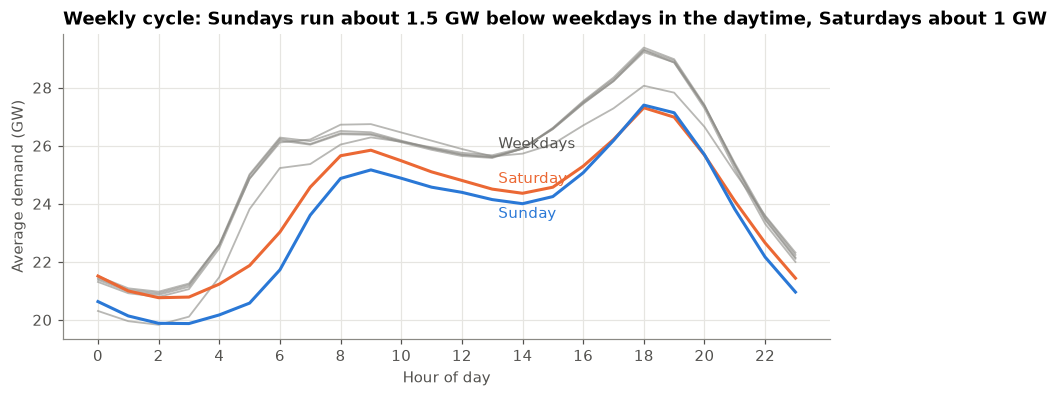

In [10]:
week = demand.groupby([demand.index.dayofweek, demand.index.hour]).mean().unstack(0) / 1000
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(9, 3.6))
for dow, colour in zip(range(7), [GREY] * 5 + [ORANGE, BLUE]):
    ax.plot(week.index, week[dow], color=colour, linewidth=2 if dow >= 5 else 1.2, alpha=1 if dow >= 5 else 0.6)
ax.annotate("Saturday", (13, week.loc[13, 5]), xytext=(4, 4), textcoords="offset points", color=ORANGE)
ax.annotate("Sunday", (13, week.loc[13, 6]), xytext=(4, -12), textcoords="offset points", color=BLUE)
ax.annotate("Weekdays", (13, week.loc[13, 2]), xytext=(4, 6), textcoords="offset points", color="#52514e")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Average demand (GW)"); ax.set_xticks(range(0, 24, 2))
ax.set_title("Weekly cycle: Sundays run about 1.5 GW below weekdays in the daytime, Saturdays about 1 GW")
fig.savefig("../figures/weekly_cycle.png")
plt.show()

## Public holidays

In [11]:
hol = sa_public_holidays(range(2022, 2027))
daily = demand.resample("D").mean().to_frame()
daily["holiday"] = [d.date() in hol for d in daily.index]
daily["dow"] = daily.index.dayofweek
# compare each weekday holiday with the average of the same weekday in the weeks around it
around = daily["demand"].rolling(29, center=True).median()
effect = (daily["demand"] / around - 1)[daily.holiday & (daily.dow < 5)]
print(f"Weekday public holidays in the data: {len(effect)}")
print(f"Typical demand on a weekday public holiday: {effect.median():.1%} vs the surrounding weeks")

Weekday public holidays in the data: 52
Typical demand on a weekday public holiday: -5.4% vs the surrounding weeks


A weekday public holiday behaves more like a weekend day: daily demand drops by about 5% on average compared with the surrounding weeks, and by more during working hours. A model that does not know the holiday calendar will over-forecast those days.

## Load shedding

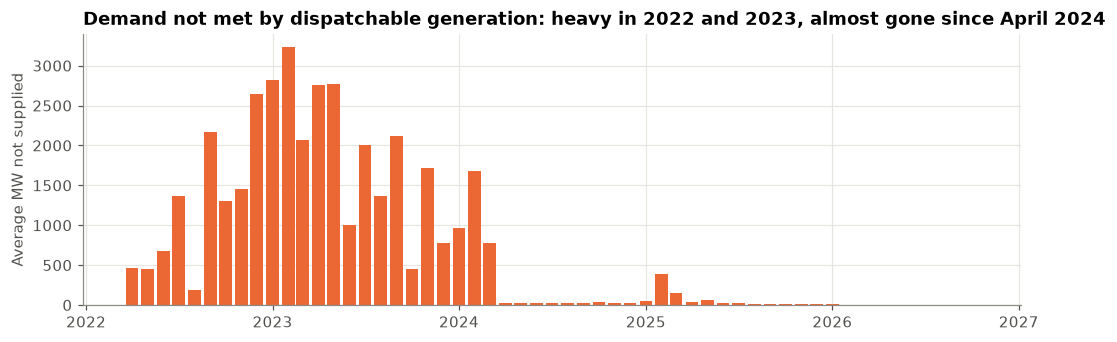

Average gap 2023: 1,913 MW;  since April 2024: 36 MW


In [12]:
unserved = (actual["Residual Demand"] - actual["Dispatchable Generation"]).clip(lower=0)
monthly_unserved = unserved.resample("MS").mean()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(monthly_unserved.index, monthly_unserved.values, width=25, color=ORANGE)
ax.set_ylabel("Average MW not supplied")
ax.set_title("Demand not met by dispatchable generation: heavy in 2022 and 2023, almost gone since April 2024")
fig.savefig("../figures/load_shedding_gap.png")
plt.show()
print(f"Average gap 2023: {unserved['2023'].mean():,.0f} MW;  since April 2024: {unserved['2024-04':].mean():,.0f} MW")

The gap between residual demand and what dispatchable plants generated tracks the load-shedding history closely: thousands of MW short through 2022 and 2023, and close to zero since load shedding was largely suspended in early 2024. Because the demand series already includes the unmet demand, it is consistent across the period and can be used for training without patching. The gap itself is not used as a feature: nobody knows next week's load shedding in advance.

## Gaps and odd values

In [13]:
print(f"Missing hours in the actual period: {demand.isna().sum()}")
z = (demand - demand.rolling(24 * 7, center=True).median()) / demand.rolling(24 * 7, center=True).std()
print(f"Hours more than 5 rolling standard deviations from the weekly median: {(z.abs() > 5).sum()}")

Missing hours in the actual period: 0
Hours more than 5 rolling standard deviations from the weekly median: 0


## Findings

1. **Trend:** demand on the Eskom system is falling, about 14% lower in 2026 than in 2022, with rooftop solar a large part of it.
2. **Cycles:** strong daily (morning and evening peaks), weekly (weekends lower) and yearly (winter peak) patterns.
3. **Holidays:** a weekday public holiday cuts daily demand by about 5%.
4. **Structural change:** the midday dip deepens each year as solar grows; the winter evening peak is the critical hour.
5. **Data quality:** no missing hours, no extreme spikes. Load shedding is visible in the gap columns, but the demand target is consistent through it.

In [14]:
hourly = pd.DataFrame({"demand": demand, "eskom_forecast": actual["RSA Contracted Forecast"]})
hourly["holiday"] = [t.date() in hol for t in hourly.index]
hourly.to_parquet("../data/processed/hourly.parquet")
hourly.shape

(39600, 3)